# Origraphi — Pilot Study Analysis

Pilot of the online study, comparing **unfolded** (standard BioFabric) and **folded** (Origraphi edge
folding) between subjects. The notebook describes response time, accuracy and NASA-TLX per task and
condition, and estimates effect sizes and sample sizes to plan the online study.

Tasks (3 trials each):

- **T1 – Adjacency** (`task1`): select the nodes connected to the highlighted node.
- **T2 – Common neighbors** (`task2`): select the common neighbors of two highlighted nodes.
- **T3 – Size** (`task3`): estimate the number of edges in the graph.

The first cell loads the libraries and sets the file paths and colours (folded = blue, unfolded = orange).

In [1]:
# imports and settings
import json
import warnings

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.power import TTestIndPower

warnings.filterwarnings("ignore", message="Precision loss occurred in moment calculation")

sns.set_theme(style="whitegrid")
rng = np.random.default_rng(42)

DATA_PATH = "data/biofabric-study-pilot_all_tidy.csv"
EDGE_TRUTH_PATH = "estimation_graph_truth.csv"
NASA_SUBSCALES = ["mental-demand", "physical-demand", "temporal-demand",
                  "performance", "effort", "frustration"]
COND_PALETTE = {"folded": "#4C72B0", "unfolded": "#DD8452"}
TASK_PALETTE = {"task1": "#55A868", "task2": "#8172B2", "task3": "#937860", "overall": "#333333"}


## Preprocessing

Loads the reVISit export, relabels the conditions, and keeps only participants with a complete
session, so that everyone contributes all trials. The next cell scores each trial:

- **Tasks 1 and 2:** correct if the selected nodes exactly match the correct answer.
- **Task 3:** 100 − the absolute percentage error of the edge-count estimate, using the true edge
  counts in `estimation_graph_truth.csv`.

In [2]:
df = pd.read_csv(DATA_PATH, dtype=str, keep_default_na=False)
df["condition"] = df["condition"].replace({"collapsed": "folded", "normal": "unfolded"})  # reVISit labels -> Origraphi names
df["trialOrder"] = pd.to_numeric(df["trialOrder"], errors="coerce")
df["duration"] = pd.to_numeric(df["duration"], errors="coerce")

status_counts = df.groupby("participantId")["status"].value_counts().unstack(fill_value=0)
finishers = status_counts[status_counts.get("completed", 0) >= 27].index
df = df[df["participantId"].isin(finishers)].copy()
completed = df[df["status"] == "completed"].copy()

n_folded = df.loc[df["condition"] == "folded", "participantId"].nunique()
n_unfolded = df.loc[df["condition"] == "unfolded", "participantId"].nunique()
print(f"N = {len(finishers)} participants with a full session ({n_folded} folded, {n_unfolded} unfolded)")


N = 15 participants with a full session (9 folded, 6 unfolded)


In [3]:
def parse_json_field(value):
    if value == "":
        return None
    try:
        return json.loads(value)
    except (json.JSONDecodeError, TypeError):
        return value


def as_set(value):
    parsed = parse_json_field(value)
    if parsed is None:
        return None
    return set(parsed) if isinstance(parsed, list) else {parsed}


def extract(frame, trial_regex, response_id):
    mask = (
        frame["trialId"].str.match(trial_regex)
        & (frame["status"] == "completed")
        & (frame["responseId"] == response_id)
    )
    return frame.loc[mask].copy()


edge_truth = pd.read_csv(EDGE_TRUTH_PATH)[["graph_file", "n_edges"]]

task1 = extract(completed, r"^task1_component_", "graphVis")
task1["correct"] = task1.apply(lambda r: as_set(r["answer"]) == as_set(r["correctAnswer"]), axis=1)

task2 = extract(completed, r"^task2_component_", "graphVis")
task2["correct"] = task2.apply(lambda r: as_set(r["answer"]) == as_set(r["correctAnswer"]), axis=1)

task3 = extract(completed, r"^task3_component_", "task3-numerical")
task3["graph_file"] = task3["parameters_graphDataPath"].str.extract(r"([^/]+\.json)$")
task3 = task3.merge(edge_truth, on="graph_file", how="left")
task3["estimate"] = pd.to_numeric(task3["answer"], errors="coerce")
task3["accuracy_pct"] = (100 - (task3["estimate"] - task3["n_edges"]).abs() / task3["n_edges"] * 100).clip(lower=0)


Averages each participant's 3 trials per task into one value per participant and task, so that
trials from the same person are not counted as independent observations.

In [4]:
def per_participant(frame, value_col, scale=1.0):
    return (
        frame.groupby(["participantId", "condition"])[value_col].mean().mul(scale)
        .rename("value").reset_index()
    )

accuracy = pd.concat([
    per_participant(task1, "correct", 100).assign(task="task1"),
    per_participant(task2, "correct", 100).assign(task="task2"),
    per_participant(task3, "accuracy_pct").assign(task="task3"),
], ignore_index=True)

durations = pd.concat([
    per_participant(task1, "duration").assign(task="task1"),
    per_participant(task2, "duration").assign(task="task2"),
    per_participant(task3, "duration").assign(task="task3"),
], ignore_index=True)


## Response time per task

Bars show the mean per condition with a 95% CI; dots are individual participants.

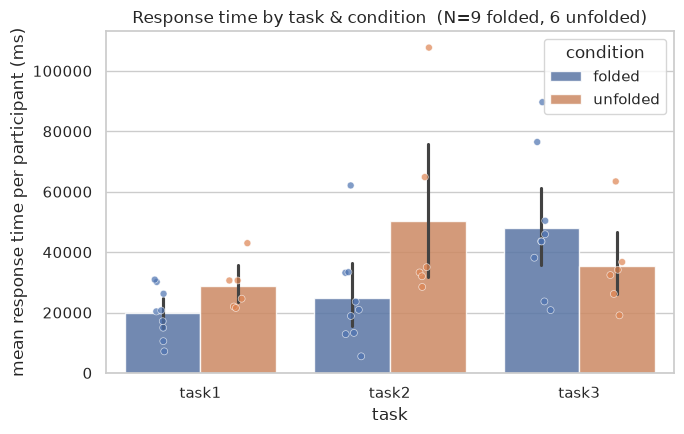

In [5]:
plt.figure(figsize=(7, 4.5))
sns.barplot(data=durations, x="task", y="value", hue="condition", palette=COND_PALETTE, errorbar="ci", alpha=0.85)
sns.stripplot(data=durations, x="task", y="value", hue="condition", palette=COND_PALETTE,
              dodge=True, legend=False, alpha=0.7, size=5, linewidth=0.5, edgecolor="white")
plt.ylabel("mean response time per participant (ms)")
plt.title(f"Response time by task & condition  (N={n_folded} folded, {n_unfolded} unfolded)")
plt.tight_layout()
plt.show()


## Accuracy per task

Same layout as the response-time plot.

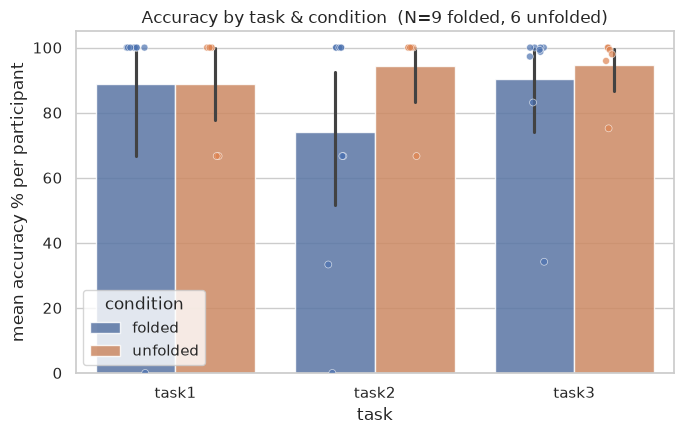

In [6]:
plt.figure(figsize=(7, 4.5))
sns.barplot(data=accuracy, x="task", y="value", hue="condition", palette=COND_PALETTE, errorbar="ci", alpha=0.85)
sns.stripplot(data=accuracy, x="task", y="value", hue="condition", palette=COND_PALETTE,
              dodge=True, legend=False, alpha=0.7, size=5, linewidth=0.5, edgecolor="white")
plt.ylabel("mean accuracy % per participant")
plt.title(f"Accuracy by task & condition  (N={n_folded} folded, {n_unfolded} unfolded)")
plt.tight_layout()
plt.show()


## NASA-TLX subscales per task

NASA-TLX is filled in after each task block. The block order differs between participants, so the
first cell assigns each questionnaire to the task block before it. The second cell plots each
subscale by task and condition.

In [7]:
order_df = df.loc[df["trialOrder"].notna(), ["participantId", "trialOrder", "trialId"]].drop_duplicates()
order_df["task_num"] = order_df["trialId"].str.extract(r"^task([123])_component_")[0]
order_df = order_df.sort_values(["participantId", "trialOrder"])

block_labels = []
for pid, group in order_df.groupby("participantId"):
    current_task = None
    for _, row in group.iterrows():
        if pd.notna(row["task_num"]):
            current_task = row["task_num"]
        if row["trialId"] == "$nasa-tlx.components.nasa-tlx":
            block_labels.append({"participantId": pid, "trialOrder": row["trialOrder"], "task": current_task})
block_labels = pd.DataFrame(block_labels)

tlx = completed[
    (completed["trialId"] == "$nasa-tlx.components.nasa-tlx")
    & (completed["responseId"].isin(NASA_SUBSCALES))
].copy()
tlx["score"] = pd.to_numeric(tlx["answer"], errors="coerce")
tlx = tlx.merge(block_labels, on=["participantId", "trialOrder"], how="left")
tlx["task"] = "task" + tlx["task"]


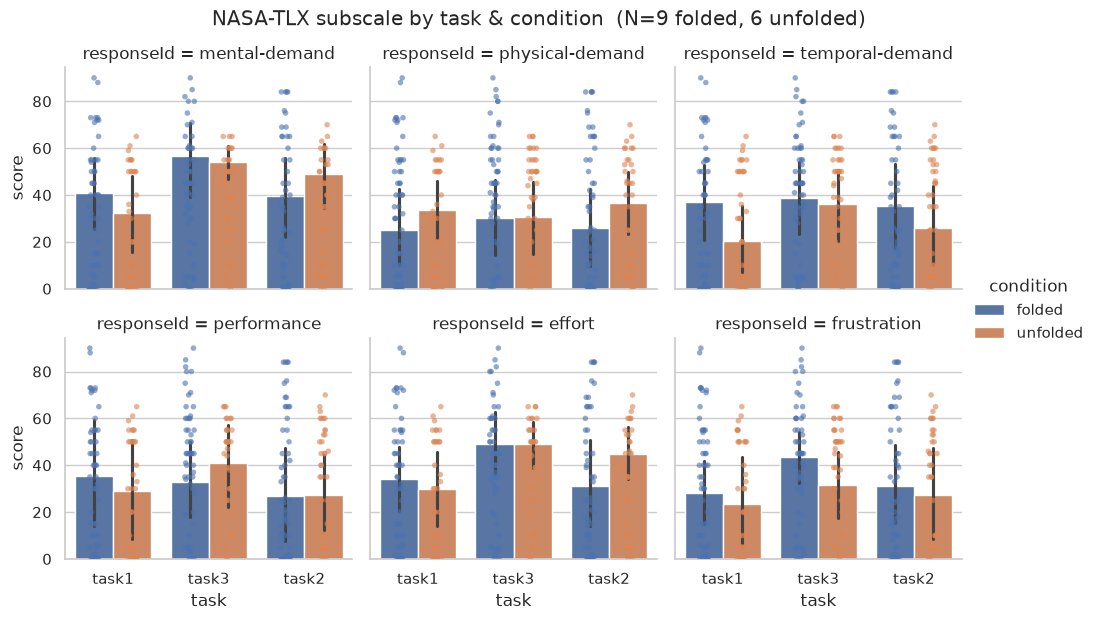

In [8]:
g = sns.catplot(
    data=tlx, x="task", y="score", hue="condition", col="responseId",
    palette=COND_PALETTE, kind="bar", errorbar="ci", col_wrap=3, height=3, aspect=1.1,
)
for ax in g.axes.flat:
    sns.stripplot(data=tlx, x="task", y="score", hue="condition", palette=COND_PALETTE,
                  dodge=True, legend=False, alpha=0.6, size=4, ax=ax,
                  order=["task1", "task2", "task3"])
g.figure.suptitle(f"NASA-TLX subscale by task & condition  (N={n_folded} folded, {n_unfolded} unfolded)", y=1.03)
plt.show()


## Effect sizes and sample-size estimates

Computes Cohen's *d* (folded − unfolded) for accuracy, response time and RTLX, per task and pooled over
the three tasks (`overall`). For the pooled values it prints *d* with a bootstrap 95% CI, and the
participants per group needed for 80% power at α = .05 and at a Bonferroni-corrected α = .05/9
(for the 9 per-task tests). With 15 participants, these are rough estimates for planning only.

In [9]:
accuracy_power = accuracy.assign(category="Accuracy %")
duration_power = durations.assign(category="Response time (ms)")
rtlx_power = (
    tlx.groupby(["participantId", "condition", "task"])["score"].mean()
    .rename("value").reset_index().assign(category="RTLX (per task)")
)
power_long = pd.concat([accuracy_power, duration_power, rtlx_power], ignore_index=True)

# pooled "overall" value per participant: mean across their 3 tasks, one row per metric family
overall_rows = (
    power_long.groupby(["participantId", "condition", "category"])["value"].mean()
    .reset_index().assign(task="overall")
)
power_long = pd.concat([power_long, overall_rows], ignore_index=True)

CATEGORIES = ["Accuracy %", "Response time (ms)", "RTLX (per task)"]
TASK_ORDER = ["task1", "task2", "task3", "overall"]
ALPHA = 0.05
N_COMPARISONS = 9  # the original task1/2/3 x accuracy/response-time/RTLX set
ALPHA_BONF = ALPHA / N_COMPARISONS


def cohens_d(a, b):
    a, b = np.asarray(a), np.asarray(b)
    pooled_sd = np.sqrt(((len(a) - 1) * a.var(ddof=1) + (len(b) - 1) * b.var(ddof=1)) / (len(a) + len(b) - 2))
    if pooled_sd == 0:
        return np.nan  # a resample with zero variance in both groups -> d undefined, not zero
    return (a.mean() - b.mean()) / pooled_sd


def bootstrap_d_ci(a, b, n_boot=2000, ci=95):
    a, b = np.asarray(a), np.asarray(b)
    ds = np.array([
        cohens_d(rng.choice(a, size=len(a), replace=True), rng.choice(b, size=len(b), replace=True))
        for _ in range(n_boot)
    ])
    half = (100 - ci) / 2
    return np.nanpercentile(ds, [half, 100 - half])


analyzer = TTestIndPower()

print(f"Pooled across tasks (N={n_folded} folded, {n_unfolded} unfolded), the 'as a whole' read per metric:")
for category in CATEGORIES:
    g = power_long[(power_long["category"] == category) & (power_long["task"] == "overall")]
    a = g.loc[g["condition"] == "folded", "value"]
    b = g.loc[g["condition"] == "unfolded", "value"]
    d = cohens_d(a, b)
    lo, hi = bootstrap_d_ci(a, b)
    n_05 = analyzer.solve_power(effect_size=abs(d), alpha=ALPHA, power=0.8, ratio=1.0)
    n_bonf = analyzer.solve_power(effect_size=abs(d), alpha=ALPHA_BONF, power=0.8, ratio=1.0)
    print(f"  {category}: d={d:.2f} (95% bootstrap CI [{lo:.2f}, {hi:.2f}]) "
          f"-> n/group: {np.ceil(n_05):.0f} @ α=.05, {np.ceil(n_bonf):.0f} @ Bonferroni α={ALPHA_BONF:.4f}")


Pooled across tasks (N=9 folded, 6 unfolded), the 'as a whole' read per metric:
  Accuracy %: d=-0.39 (95% bootstrap CI [-1.04, 1.01]) -> n/group: 107 @ α=.05, 178 @ Bonferroni α=0.0056
  Response time (ms): d=-0.49 (95% bootstrap CI [-1.57, 0.65]) -> n/group: 68 @ α=.05, 113 @ Bonferroni α=0.0056


  RTLX (per task): d=0.06 (95% bootstrap CI [-1.08, 1.08]) -> n/group: 4847 @ α=.05, 8069 @ Bonferroni α=0.0056


## Effect sizes per task

Plots *d* per task and pooled: the dot is the point estimate, the whisker its bootstrap 95% CI.

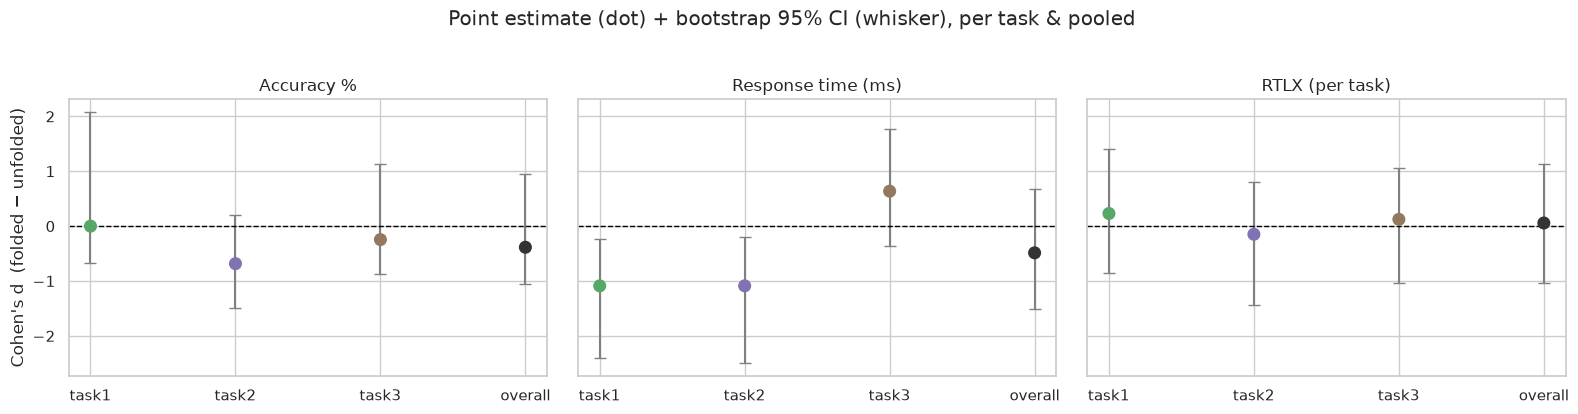

In [10]:
d_rows = []
for category in CATEGORIES:
    cat_group = power_long[power_long["category"] == category]
    for task in TASK_ORDER:
        g = cat_group[cat_group["task"] == task]
        a = g.loc[g["condition"] == "folded", "value"]
        b = g.loc[g["condition"] == "unfolded", "value"]
        d = cohens_d(a, b)
        lo, hi = bootstrap_d_ci(a, b)
        d_rows.append({"category": category, "task": task, "d": d, "lo": lo, "hi": hi})
d_summary = pd.DataFrame(d_rows)

fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
for ax, category in zip(axes, CATEGORIES):
    g = d_summary[d_summary["category"] == category].set_index("task").loc[TASK_ORDER].reset_index()
    ax.errorbar(g["task"], g["d"], yerr=[g["d"] - g["lo"], g["hi"] - g["d"]],
                fmt="none", ecolor="gray", capsize=4, zorder=2)
    ax.scatter(g["task"], g["d"], c=[TASK_PALETTE[t] for t in g["task"]], s=70, zorder=3)
    ax.axhline(0, color="black", linestyle="--", linewidth=1)
    ax.set_title(category)
axes[0].set_ylabel("Cohen's d  (folded − unfolded)")
fig.suptitle("Point estimate (dot) + bootstrap 95% CI (whisker), per task & pooled", y=1.03)
plt.tight_layout()
plt.show()


## Bootstrap power curves

Resamples the pilot values at 5–60 participants per group, runs a t-test on each resample and records
how often it is significant. This estimates power without assuming normally distributed data.

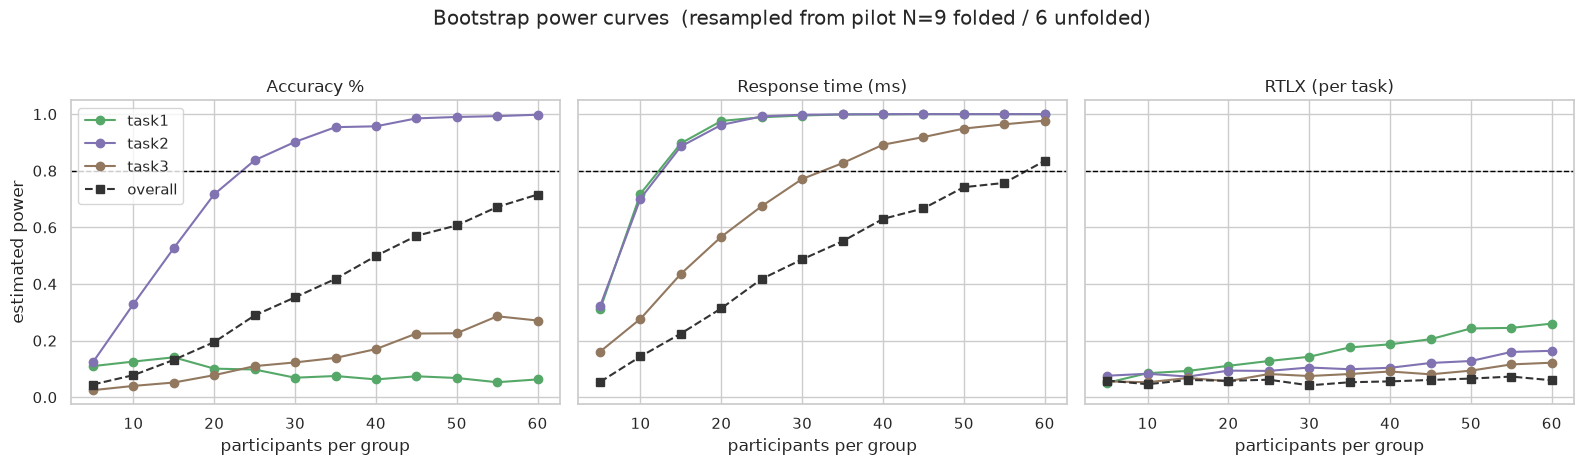

In [11]:
def bootstrap_power_curve(a, b, candidate_ns, alpha=0.05, n_boot=1000):
    a, b = a.to_numpy(), b.to_numpy()
    power = []
    for n in candidate_ns:
        hits = 0
        for _ in range(n_boot):
            sample_a = rng.choice(a, size=n, replace=True)
            sample_b = rng.choice(b, size=n, replace=True)
            _, p = stats.ttest_ind(sample_a, sample_b)
            hits += p < alpha
        power.append(hits / n_boot)
    return np.array(power)


candidate_ns = np.arange(5, 61, 5)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
for ax, category in zip(axes, CATEGORIES):
    cat_group = power_long[power_long["category"] == category]
    for task in TASK_ORDER:
        g = cat_group[cat_group["task"] == task]
        a = g.loc[g["condition"] == "folded", "value"]
        b = g.loc[g["condition"] == "unfolded", "value"]
        power = bootstrap_power_curve(a, b, candidate_ns)
        style = {"marker": "o", "linestyle": "-"} if task != "overall" else {"marker": "s", "linestyle": "--"}
        ax.plot(candidate_ns, power, color=TASK_PALETTE[task], label=task, **style)
    ax.axhline(0.8, color="black", linestyle="--", linewidth=1)
    ax.set_title(category)
    ax.set_xlabel("participants per group")
axes[0].set_ylabel("estimated power")
axes[0].legend(title=None)
fig.suptitle(f"Bootstrap power curves  (resampled from pilot N={n_folded} folded / {n_unfolded} unfolded)", y=1.03)
plt.tight_layout()
plt.show()


## How to read the results

- **Descriptive plots:** compare the conditions within each task. With 9 folded and 6 unfolded
  participants, wide and overlapping CIs are expected.
- **Effect sizes:** a negative *d* means lower values with folding (e.g. faster response times).
  A CI that crosses 0 means even the direction of the effect is uncertain, so treat the matching
  sample size as speculative.
- **Power curves:** where a line crosses the dashed 80% line is the estimated number of participants
  per group needed for that measure. `overall` usually needs the fewest, because pooling over tasks
  reduces noise.
- These estimates come from 15 participants; they guided the sample size of the online study but are
  not firm targets.